<!-- # Copyright (c) 2026 takotime808 -->
# Replicating Mainini et al.: the AVT-331 L1 multi-fidelity benchmarks

This notebook tries to reproduce the findings of

> Mainini, L., Serani, A., Rumpfkeil, M. P., Minisci, E., Quagliarella, D., Pehlivan, H., Yildiz, S.,
> Ficini, S., Pellegrini, R., Di Fiore, F., Bryson, D., Nikbay, M., Diez, M., & Beran, P.
> *Analytical Benchmark Problems for Multifidelity Optimization Methods*.
> [arXiv:2204.07867](https://arxiv.org/abs/2204.07867) (2022). Journal version:
> *Analytical benchmark problems and methodological framework for the assessment and comparison
> of multifidelity optimization methods*, Archives of Computational Methods in Engineering
> ([doi:10.1007/s11831-025-10392-8](https://doi.org/10.1007/s11831-025-10392-8)).

This is reference **XC4** in `docs/references.rst`. `examples/mf_surrogates.ipynb` already uses its
4-level Forrester problem. This notebook covers the whole suite.

**The authors' code.** The NATO AVT-331 group published the benchmark functions (Matlab, Fortran and
Python) and a table of reference optima at
[gitlab.com/qudo046/avt-331-l1-benchmarks](https://gitlab.com/qudo046/avt-331-l1-benchmarks) (GPL-2.0).
The repository holds only the *test functions*. The 19 optimization methods compared in the paper
belong to the individual groups and are not published there. So the replication has two parts:

1. **Benchmark definitions, fully reproducible.** Every problem is implemented in the package
   (`multioutreg.active.benchmarks.L1_BENCHMARKS`, vectorized NumPy written from the paper's equations).
   Each is checked against the reference optima the authors published (`AVT331_L1Problem_MinMaxValues.csv`)
   and against Table 4 of the paper. The places where the paper's text and the official code disagree are
   listed.
2. **Method comparison, reproducible in kind.** The paper's evaluation protocol is applied to methods
   built from this package's surrogates: the budgets and cost ratios of Table 2, the error metrics
   $\mathcal{E}_x, \mathcal{E}_f, \mathcal{E}_t, \mathcal{E}_{\rm RMSE}$, checkpoints at 25/50/75/100 %
   of budget, and 10 repetitions. Each method is matched to its nearest counterpart in the paper. The
   results are placed beside the paper's Table 5 (parsed from the arXiv TeX source), and the paper's
   qualitative claims are checked one by one.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")  # keep BLAS/OpenMP single-threaded; parallelism comes from joblib
import lightgbm  # noqa: F401  (imported first to avoid an OpenMP clash on macOS)

import time
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from joblib import Parallel, delayed
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import qmc

warnings.filterwarnings("ignore")

from multioutreg.surrogates import AdditiveCorrectionVFM, GaussianProcessSurrogate
from multioutreg.active.acquisition import expected_improvement
from multioutreg.active.multi_fidelity import effective_costs, fidelity_info, level_trust, mf_expected_improvement

N_REPS = 10          # the paper uses 10 runs for stochastic methods
N_JOBS = -1
RUN_HIGH_D = False   # True also runs the surrogate methods on MF2.2/2.3/3.2/3.3 (5-D, 10-D); much slower
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## 1. The benchmark problems

The 14 problems are in the package: `multioutreg.active.benchmarks` holds them as `L1_BENCHMARKS`
(`get_benchmark("mf1.1")` … `get_benchmark("mf6")`). They come with the costs and budgets of the
paper's Table 2, and the ranges and optima of its Table 4 at the precision of the authors' CSV. The
library's own tests check them against that CSV. This notebook checks them again (Section 3) and
then uses them for the study.

| ID | Problem | $D$ | Bounds | Levels | Feature stressed |
|---|---|---|---|---|---|
| MF1.1 | Forrester | 1 | $[0,1]$ | 4 | Local/global optima |
| MF1.2 | Jump Forrester | 1 | $[0,1]$ | 2 | Discontinuity |
| MF2.1–2.3 | Rosenbrock | 2, 5, 10 | $[-2,2]^D$ | 3 | Curved valley, scaling with $D$ |
| MF3.1–3.3 | Shifted-rotated Rastrigin | 2, 5, 10 | $[-0.1,0.2]^D$ | 3 | Multimodality |
| MF4.1–4.3 | Heterogeneous | 1, 2, 3 | $[0,1]^D$ | 2 | Nonlinear level-to-level relation |
| MF5.1, 5.2 | Springs / spring-masses (RK4) | 2, 4 | $[1,4]^D$ | 2 | ODE, time-step fidelity |
| MF6 | Paciorek with noise | 2 | $[0.3,1]^2$ | 2 | Noise, localized multimodality |

The `Benchmark` objects name levels cheapest first (`"lo"` … `"hi"`). The raw functions
(`forrester_mf`, `rosenbrock_mf`, …) keep the paper's numbering, in which `level=1` is $f_1$, the
**highest** fidelity. The study below works in the unit cube, as the paper's metrics do, so the
`Problem` wrapper maps $u \in [0,1]^D$ to each problem's bounds. It calls the raw functions with the
paper's level numbers, which lets every run pass its own random generator for MF6's noise.

In [2]:
from multioutreg.active import L1_BENCHMARKS, get_benchmark
from multioutreg.active.benchmarks import (
    forrester_mf, heterogeneous_mf, jump_forrester, paciorek, rastrigin_mf, rosenbrock_mf, spring_masses, springs,
)
from multioutreg.metrics import design_error

RAW = {"mf1.1": forrester_mf, "mf1.2": jump_forrester, "mf2.1": rosenbrock_mf, "mf2.2": rosenbrock_mf,
       "mf2.3": rosenbrock_mf, "mf3.1": rastrigin_mf, "mf3.2": rastrigin_mf, "mf3.3": rastrigin_mf,
       "mf4.1": heterogeneous_mf, "mf4.2": heterogeneous_mf, "mf4.3": heterogeneous_mf,
       "mf5.1": springs, "mf5.2": spring_masses, "mf6": paciorek}
NAMES = {"mf1.1": "Forrester", "mf1.2": "Jump Forrester", "mf2": "Rosenbrock", "mf3": "Rastrigin",
         "mf4": "Heterogeneous", "mf5.1": "Springs", "mf5.2": "Spring-masses", "mf6": "Paciorek"}


@dataclass
class Problem:
    """A library L1 benchmark seen through the unit cube, with the paper's level numbering."""

    key: str

    def __post_init__(self):
        self.bench = get_benchmark(self.key, seed=0)
        self.pid = self.key.upper()
        self.name = NAMES.get(self.key, NAMES.get(self.key[:3]))
        self.raw = RAW[self.key]
        self.D = self.bench.n_features
        self.budget = self.bench.budget
        self.costs = [self.bench.costs[lvl] for lvl in reversed(self.bench.levels)]  # costs[0] is f_1
        self.fmin, self.fmax = self.bench.minimum, self.bench.maximum
        self.noisy = self.raw is paciorek

    def x(self, U):
        lo, hi = self.bench.bounds[:, 0], self.bench.bounds[:, 1]
        return lo + np.atleast_2d(np.asarray(U, dtype=np.float64)) * (hi - lo)

    def fn(self, U, level=1, rng=None):
        """Paper level: 1 is the highest fidelity; 0 is the noise-free truth."""
        if self.noisy:
            return paciorek(self.x(U), level, rng=rng)
        return self.raw(self.x(U), max(level, 1))

    def hi(self, U, rng=None):
        return self.fn(U, 1, rng)

    def lo(self, U, rng=None):
        return self.fn(U, len(self.costs), rng)

    def truth(self, U):
        return self.fn(U, 0)

    def dist_to_opt(self, U):
        """Unit-cube distance from each row of U to the nearest global minimizer."""
        b = self.bench
        return np.array([design_error(self.x(u[None]), b.argmin, bounds=b.bounds, distance=b.argmin_distance) * np.sqrt(self.D)
                         for u in np.atleast_2d(U)])


PROBLEMS = {p.pid: p for p in (Problem(k) for k in L1_BENCHMARKS)}
PIDS = list(PROBLEMS)

pd.DataFrame([{"ID": p.pid, "Problem": p.name, "D": p.D, "Budget": p.budget,
               "Cost ratios": ", ".join(f"{c:g}" for c in p.costs), "f_min": p.fmin, "f_max": p.fmax}
              for p in PROBLEMS.values()]).set_index("ID")

,Problem,D,Budget,Cost ratios,f_min,f_max
ID,,,,,,
MF1.1,Forrester,1,100,"1, 0.5, 0.1, 0.05",-6.021,15.83
MF1.2,Jump Forrester,1,100,"1, 0.2",-0.9863,25.83
MF2.1,Rosenbrock,2,200,"1, 0.5, 0.1",0,3609
MF2.2,Rosenbrock,5,500,"1, 0.5, 0.1",0,1.444e+04
MF2.3,Rosenbrock,10,1000,"1, 0.5, 0.1",0,3.248e+04
MF3.1,Rastrigin,2,200,"1, 0.0625, 0.00391",0,4.02
MF3.2,Rastrigin,5,500,"1, 0.0625, 0.00391",0,10.05
MF3.3,Rastrigin,10,1000,"1, 0.0625, 0.00391",0,20.1
MF4.1,Heterogeneous,1,100,"1, 0.2",-0.625,0.3615


## 2. Paper text vs. official code

The official Python implementation (`Python/L1Problems.py` in the GitLab repository) was read line by
line. The library functions follow the **code** wherever it disagrees with the arXiv text, because the
authors' reference optima were computed with the code.

| Problem | arXiv text | Official code (used here) | Effect |
|---|---|---|---|
| MF2 Rosenbrock $f_3$ | Denominator $10 + \sum_i 0.25\,x_1$ | $10 + \sum_i 0.25\,x_i$ | Typo in the text ($x_1$ for $x_i$) |
| MF1.2 Jump Forrester $f_2$, $x > 0.5$ | $0.5 f_1 + 10(x-0.5) - 2$, with $f_1$ including the $+10$ jump | $0.5 f_1 + 10(x-0.5) - 7$ | Code's right branch is 5 lower. The code equals the text if $f_1$ there means the jump-free Forrester |
| MF3 Rastrigin rotation | $R(\theta)$ "extended to arbitrary dimension" (Aguilera-Perez) | Identity, except a 2×2 rotation of the **last two** coordinates | In 5-D and 10-D only $x_{D-1}, x_D$ are coupled |
| MF6 Paciorek | $\sin\left(\prod_i x_i\right)^{-1}$ | $\sin\left(1/(x_1 x_2)\right)$ | The text's notation is ambiguous. The code (and Table 4's optimum curves) use $\sin(1/(x_1x_2))$ |
| MF6 levels | $f_1$, $f_2$ | Level 0 = noise-free, 1 = $f_1$ + noise, 2 = $f_2$ + noise | Noise-free level 0 is used for the metrics |
| Reference CSV `fMax` | Table 4 lists $f_{\max} > 0$ | CSV stores $-f_{\max}$ (the minimum of $-f$) | Sign convention only |

The code also has a `Mass` variant (springs fixed, masses as design variables) that the paper does not
use.

## 3. Validation of the definitions

**3a. Against the authors' reference optima.** The CSV in the repository lists the minimizer
$u_{\min}$ (unit cube) and $f_{\min}$ for 13 cases, computed by the authors with dual annealing followed
by SLSQP on their Python code. Evaluating our functions at their minimizers should give their $f_{\min}$.

In [3]:
# Rows of AVT331_L1Problem_MinMaxValues.csv (unit-cube minimizer, f_min, -f_max).
REFERENCE_CSV = {
    "MF1.1": ([0.757248751], -6.020740056, -15.82973195),
    "MF4.1": ([0.275501812], -0.624998901, -0.361513623),
    "MF2.1": ([0.75, 0.75], 0.0, -3609),
    "MF3.1": ([2 / 3] * 2, 0.0, -4.020040611),
    "MF4.2": ([0, 0], -0.562712306, -1.835000108),
    "MF5.1": ([0.489133693, 0.39774848], -0.999999999, -1),
    "MF4.3": ([0, 0.061716432, 0.012401164], -0.562712306, -4.359413062),
    "MF5.2": ([0, 0.982006049, 1, 0.76209219], -1, -1),
    "MF2.2": ([0.75] * 5, 0.0, -14436),
    "MF3.2": ([2 / 3] * 5, 0.0, -10.05010153),
    "MF2.3": ([0.75] * 10, 0.0, -32481),
    "MF3.3": ([2 / 3] * 10, 0.0, -20.10020305),
}
# Locations of f_max from the same file, for the cases where it is a single point.
FMAX_AT = {"MF1.1": [1.0], "MF4.1": [0.445870846], "MF2.1": [0, 0], "MF4.2": [1, 1], "MF4.3": [1, 1, 1],
           "MF3.1": [0.272956952, 0.405672059], "MF2.2": [0] * 5, "MF2.3": [0] * 10}

rows = []
for pid, (u, fmin_ref, neg_fmax) in REFERENCE_CSV.items():
    p = PROBLEMS[pid]
    f_at = p.truth(np.array([u]))[0, 0]
    r = {"ID": pid, "f_min (CSV)": fmin_ref, "ours at CSV u_min": f_at, "|diff|": abs(f_at - fmin_ref)}
    if pid in FMAX_AT:
        g = p.truth(np.array([FMAX_AT[pid]]))[0, 0]
        r.update({"f_max (CSV, sign fixed)": -neg_fmax, "ours at CSV u_max": g, "|diff max|": abs(g + neg_fmax)})
    rows.append(r)
check_csv = pd.DataFrame(rows).set_index("ID")
check_csv

,f_min (CSV),ours at CSV u_min,|diff|,"f_max (CSV, sign fixed)",ours at CSV u_max,|diff max|
ID,,,,,,
MF1.1,-6.021,-6.021,2.329e-10,15.83,15.83,4.026e-09
MF4.1,-0.625,-0.625,2.822e-10,0.3615,0.3615,3.737e-11
MF2.1,0,0,0,3609,3609,0
MF3.1,0,0,0,4.02,4.02,9.427e-11
MF4.2,-0.5627,-0.5627,1.708e-10,1.835,1.835,8.347e-11
MF5.1,-1,-1,2.98e-10,NaN,NaN,NaN
MF4.3,-0.5627,-0.5627,1.708e-10,4.359,4.359,3.402e-10
MF5.2,-1,-1,2.757e-11,NaN,NaN,NaN
MF2.2,0,0,0,1.444e+04,1.444e+04,0


**3b. Independent global search.** The CSV does not cover MF1.2 (Jump Forrester) or MF6 (Paciorek). For
these, and as an independent check on the low-dimensional cases, a global search (bounded scalar search
in 1-D; otherwise a $2^{14}$-point Sobol sweep followed by L-BFGS-B from the 5 best points) is run on our own functions and compared with Table 4.

In [4]:
TABLE4_FMIN = {"MF1.1": -6.0207, "MF1.2": -0.9863, "MF2.1": 0.0, "MF3.1": 0.0, "MF4.1": -0.625, "MF4.2": -0.56271,
               "MF4.3": -0.56271, "MF5.1": -1.0, "MF5.2": -1.0, "MF6": -1.0}
TABLE4_X = {"MF1.1": "0.75752", "MF1.2": "0.14260", "MF2.1": "{1, 1}", "MF3.1": "{0.1, 0.1}", "MF4.1": "0.27550",
            "MF4.2": "x1 = 0", "MF4.3": "x1 = 0", "MF5.1": "{2.4674, 2.1932}", "MF5.2": "{1, 3.946, 4, 3.2863}",
            "MF6": "x1 x2 = 2/((3+4j) pi)"}
BOUNDS = {"MF1.1": (0, 1), "MF1.2": (0, 1), "MF2.1": (-2, 2), "MF3.1": (-0.1, 0.2), "MF4.1": (0, 1), "MF4.2": (0, 1),
          "MF4.3": (0, 1), "MF5.1": (1, 4), "MF5.2": (1, 4), "MF6": (0.3, 1)}

rows = []
for pid, f_ref in TABLE4_FMIN.items():
    p = PROBLEMS[pid]
    f = lambda u: float(p.truth(np.atleast_2d(u))[0, 0])
    if p.D == 1:
        grid = np.linspace(0, 1, 20001)
        vals = p.truth(grid[:, None])[:, 0]
        i = int(np.argmin(vals))
        r = minimize_scalar(f, bounds=(grid[max(i - 1, 0)], grid[min(i + 1, 20000)]), method="bounded",
                            options={"xatol": 1e-12})
        u_best, f_best = np.array([r.x]), r.fun
    else:
        # Vectorized Sobol sweep, then L-BFGS-B from the 5 best points.
        U = qmc.Sobol(p.D, seed=0).random(2 ** 14)
        vals = p.truth(U)[:, 0]
        best = min((minimize(f, u0, method="L-BFGS-B", bounds=[(0, 1)] * p.D, options={"ftol": 1e-15, "gtol": 1e-12})
                    for u0 in U[np.argsort(vals)[:5]]), key=lambda r: r.fun)
        u_best, f_best = best.x, best.fun
    lo, hi = BOUNDS[pid]
    rows.append({"ID": pid, "f_min (Table 4)": f_ref, "f_min found": f_best,
                 "x* found": np.round(lo + u_best * (hi - lo), 4), "x* (Table 4)": TABLE4_X[pid],
                 "dist. to optimal set (unit cube)": float(p.dist_to_opt(u_best[None])[0])})
check_global = pd.DataFrame(rows).set_index("ID")
check_global

,f_min (Table 4),f_min found,x* found,x* (Table 4),dist. to optimal set (unit cube)
ID,,,,,
MF1.1,-6.021,-6.021,[0.7572],0.75752,6.557e-09
MF1.2,-0.9863,-0.9863,[0.1426],0.14260,1.246e-09
MF2.1,0,3.58e-12,"[1.0, 1.0]","{1, 1}",1.048e-06
MF3.1,0,2.109e-15,"[0.1, 0.1]","{0.1, 0.1}",6.986e-09
MF4.1,-0.625,-0.625,[0.2755],0.27550,1.506e-08
MF4.2,-0.5627,-0.5627,"[0.0, 0.5821]",x1 = 0,0
MF4.3,-0.5627,-0.5627,"[0.0, 0.6866, 0.2885]",x1 = 0,0
MF5.1,-1,-1,"[2.4674, 2.1932]","{2.4674, 2.1932}",6.633e-09
MF5.2,-1,-1,"[3.2647, 2.8543, 1.2267, 1.4122]","{1, 3.946, 4, 3.2863}",1.395


**3c. The fidelity levels.** These plots show the levels the paper draws in its Figures 1–7. The table
gives the Pearson correlation of each lower level with $f_1$ over a 4096-point Sobol sample, together with
its cost. A cheap level with a high correlation is where multi-fidelity methods should pay off. Two
cases work against that: the Rosenbrock $f_2$ has its valley shifted (the $(-2 - x_i)^2$ term), and the
heterogeneous problems change scale between levels as $x$ changes.

In [5]:
rows = []
for p in PROBLEMS.values():
    U = qmc.Sobol(p.D, seed=0).random(4096)
    rng = np.random.default_rng(0)
    f1 = p.truth(U)[:, 0]
    for lvl in range(2, len(p.costs) + 1):
        fl = p.fn(U, lvl, rng=rng)[:, 0] if p.noisy else p.fn(U, lvl)[:, 0]
        rows.append({"ID": p.pid, "level": f"f{lvl}", "cost": p.costs[lvl - 1], "corr with f1": np.corrcoef(f1, fl)[0, 1]})
corr = pd.DataFrame(rows).pivot(index="ID", columns="level", values="corr with f1")
corr

level,f2,f3,f4
ID,,,
MF1.1,0.9455,0.9374,0.7357
MF1.2,0.962,NaN,NaN
MF2.1,0.9999,0.9982,NaN
MF2.2,0.9999,0.9938,NaN
MF2.3,0.9999,0.9812,NaN
MF3.1,0.9722,0.9377,NaN
MF3.2,0.9724,0.9353,NaN
MF3.3,0.9726,0.9337,NaN
MF4.1,0.8643,NaN,NaN


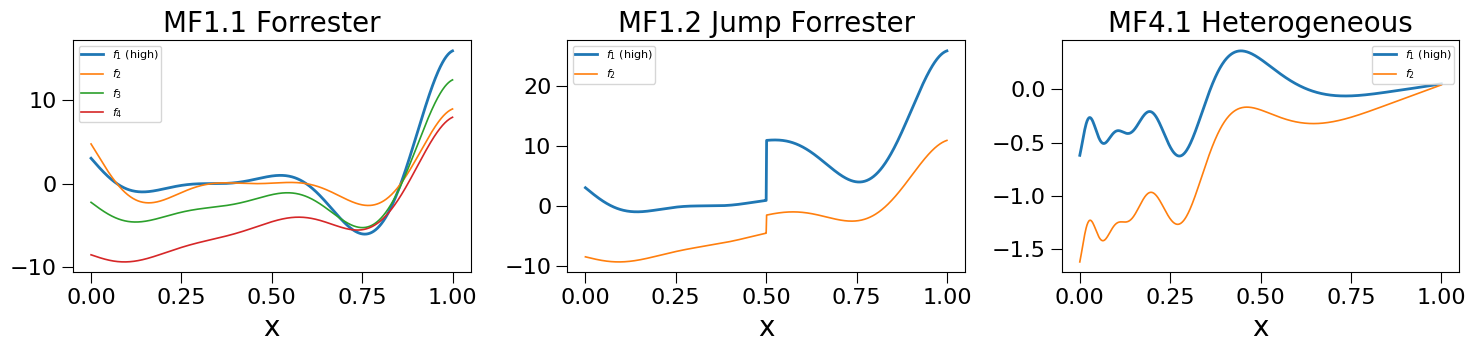

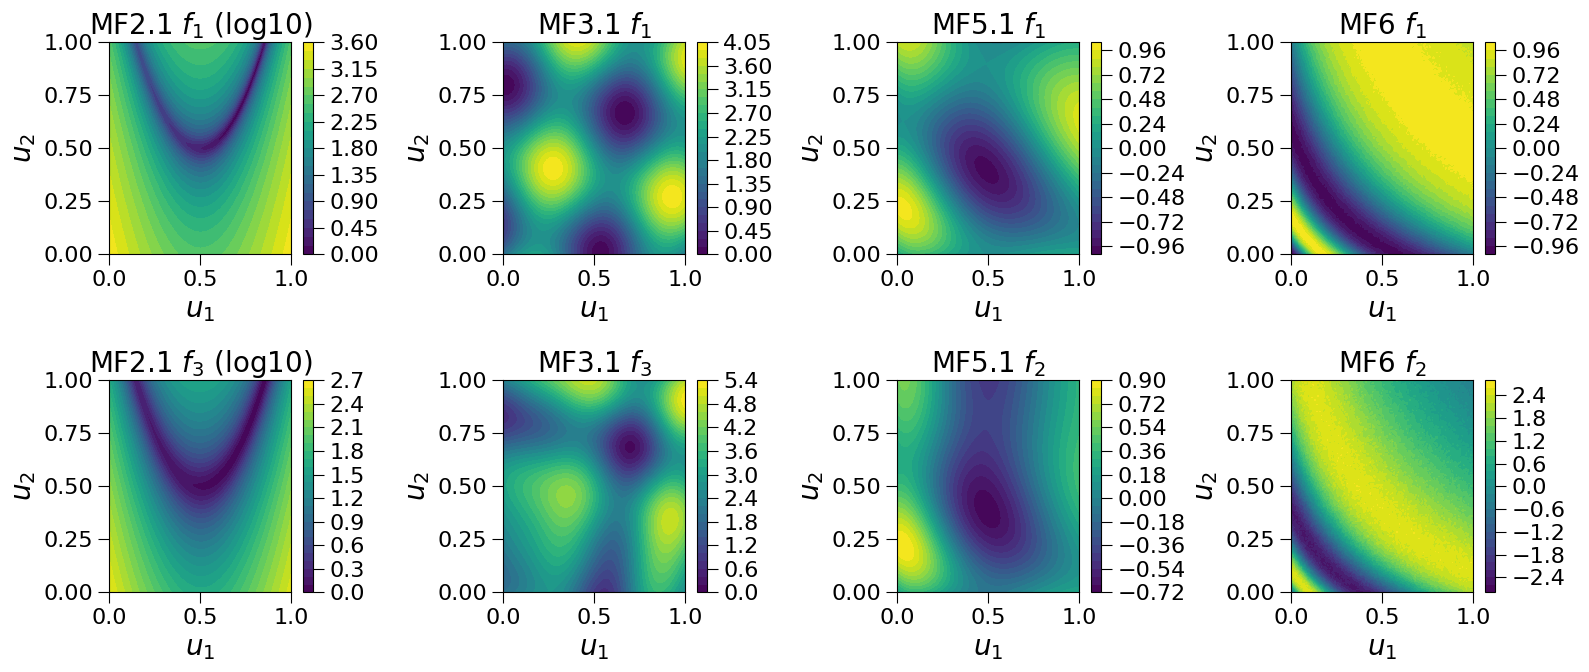

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
u = np.linspace(0, 1, 801)[:, None]
for ax, pid in zip(axes, ["MF1.1", "MF1.2", "MF4.1"]):
    p = PROBLEMS[pid]
    for lvl in range(1, len(p.costs) + 1):
        ax.plot(u[:, 0], p.fn(u, lvl)[:, 0], lw=2 if lvl == 1 else 1.2, label=f"$f_{lvl}$" + (" (high)" if lvl == 1 else ""))
    ax.set_title(f"{pid} {p.name}")
    ax.set_xlabel("x")
    ax.legend(fontsize=8)
plt.tight_layout()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
g = np.linspace(0, 1, 151)
G = np.array(np.meshgrid(g, g)).reshape(2, -1).T
for col, pid in enumerate(["MF2.1", "MF3.1", "MF5.1", "MF6"]):
    p = PROBLEMS[pid]
    rng = np.random.default_rng(0)
    L = len(p.costs)
    for row, lvl in enumerate([1, L]):
        Z = (p.fn(G, lvl, rng=rng) if p.noisy else p.fn(G, lvl))[:, 0].reshape(151, 151)
        if pid == "MF2.1":
            Z = np.log10(Z - Z.min() + 1)
        ax = axes[row, col]
        cs = ax.contourf(g, g, Z, levels=30, cmap="viridis")
        plt.colorbar(cs, ax=ax)
        ax.set_title(f"{pid} $f_{lvl}$" + (" (log10)" if pid == "MF2.1" else ""))
        ax.set_xlabel("$u_1$"); ax.set_ylabel("$u_2$")
plt.tight_layout()

## 4. Evaluation protocol (paper Section 5)

All metrics are computed in the unit cube. $\hat{x}^\star$ is the method's estimate of the optimum, and
$f_{\min}$, $f_{\max}$ come from Table 4:

$$\mathcal{E}_x = \frac{\lVert \hat{x}^\star - x^\star\rVert}{\sqrt{D}},\qquad
\mathcal{E}_f = \frac{f_1(\hat{x}^\star) - f_{\min}}{f_{\max} - f_{\min}},\qquad
\mathcal{E}_t = \sqrt{\tfrac{1}{2}(\mathcal{E}_x^2 + \mathcal{E}_f^2)},\qquad
\mathcal{E}_{\rm RMSE} = \frac{1}{f_{\max}-f_{\min}}\sqrt{\tfrac{1}{S}\textstyle\sum_i (f_1(x_i) - \hat f(x_i))^2}.$$

Cost is counted in high-fidelity equivalents. A query at level $l$ costs $\lambda_l$ (Table 2), and the
run stops when the Table 2 budget is spent. Results are recorded at 25, 50, 75 and 100 % of the budget.
Table 5 of the paper colour-codes each median error (in %) into five bands. The same bands are used
here:

| Band | Colour | Error (%) |
|---|---|---|
| `o` | orange | > 10 |
| `y` | yellow | 1 – 10 |
| `g` | green | 0.1 – 1 |
| `l` | light blue | 0.01 – 0.1 |
| `b` | dark blue | < 0.01 |

**Choices the paper leaves open, and what this notebook does:**

* $\mathcal{E}_{\rm RMSE}$ is normalized by the Table 4 range. The paper's Eq. (37) says "observed over
  the training data", but Section 5 says $f_{\min}$ and $f_{\max}$ are *provided with the benchmark*.
  It is computed on 4096 Sobol points of the noise-free $f_1$.
* For surrogate methods, $\hat{x}^\star$ is the minimizer of the surrogate mean (dense Sobol search plus
  L-BFGS-B polish). For BFGS it is the best point evaluated so far.
* $\mathcal{E}_f$ uses the noise-free $f_1$ on MF6.
* Error bars are the **median over 10 runs** (seeds 0–9). For BFGS the 10 runs are the paper's 10
  starts: the domain centre plus 9 Latin-hypercube points.

In [7]:
FRACS = (0.25, 0.5, 0.75, 1.0)


def goal_metrics(prob, x_hat):
    x_hat = np.atleast_2d(x_hat)
    ex = float(prob.dist_to_opt(x_hat)[0] / np.sqrt(prob.D))
    ef = float((prob.truth(x_hat)[0, 0] - prob.fmin) / (prob.fmax - prob.fmin))
    return {"Ex": ex, "Ef": ef, "Et": float(np.sqrt((ex ** 2 + ef ** 2) / 2))}


def nrmse(prob, model, U_test, F_test):
    pred = np.asarray(model.predict(U_test)).reshape(-1)
    return float(np.sqrt(np.mean((pred - F_test) ** 2)) / (prob.fmax - prob.fmin))


def test_set(prob, n=4096, seed=12345):
    U = qmc.Sobol(prob.D, seed=seed).random(n)
    return U, prob.truth(U)[:, 0]


def checkpoint_records(trace, prob):
    """trace: list of (cost spent, x_hat, nrmse). Use the last state within each budget fraction."""
    out = []
    for frac in FRACS:
        ok = [t for t in trace if t[0] <= frac * prob.budget + 1e-9]
        if not ok:
            out.append({"frac": frac, "Ex": np.nan, "Ef": np.nan, "Et": np.nan, "NRMSE": np.nan})
            continue
        _, x, e = ok[-1]
        out.append({"frac": frac, **goal_metrics(prob, x), "NRMSE": e})
    return out

## 5. Methods

The paper compares 19 methods from 9 groups. Their implementations are not public, so four methods are
built from this package. Each is matched to its nearest counterpart in the paper's Table 3:

| Here | Nearest in paper | What it is |
|---|---|---|
| **BFGS** | BFGS (AFRL) | L-BFGS-B with finite-difference gradients on $f_1$ only, stopped at the budget. The paper's BFGS is multi-fidelity (it uses the lowest level in a first-order corrected trust region), so this is the *surrogate-lean* baseline without that help. |
| **MF-GP-EI** | GP-EI (PoliTo) | Online. AR1 auto-regressive GP (`AdditiveCorrectionVFM`, GP at both levels) on the highest and lowest levels, as GP-EI does. Huang et al. (2006) multi-fidelity EI (`mf_expected_improvement`), with nested queries. |
| **MF-GP** | GP (ITU) | Offline. The same AR1 GP fitted to a one-shot nested Sobol design, with half the budget on $f_1$. No adaptivity. |
| **SF-GP-EI** | (not in paper) | GP + EI on $f_1$ only. The paper states that "no comparison with their single-fidelity counterpart is given", so this adds that comparison. |

**Batching.** Adaptive methods refit after each *round* of 20, not after each point, to keep the 10-run
study to minutes. Each round spends 1/20 of the remaining budget. Points are chosen greedily from one
acquisition table, and a radius of 0.05 is blanked around each choice. MF-GP-EI keeps at least 25 % of
spending on $f_1$ (as `MultiFidelityActiveLearner(min_hi_fraction=0.25)` does) and caps the lowest level
at 200 points. Without the cap, MF3's $\lambda_3 = 0.0039$ would allow tens of thousands of cheap runs.

In [8]:
def surrogate_argmin(model, D, X_obs, rng):
    """Minimizer of the surrogate mean: Sobol + observed points, best 3 polished with L-BFGS-B."""
    C = np.vstack([qmc.Sobol(D, seed=rng.integers(2 ** 31)).random(2048), X_obs])
    m = np.asarray(model.predict(C)).reshape(-1)
    f = lambda u: float(np.asarray(model.predict(u[None])).reshape(-1)[0])
    best_u, best_f = C[np.argmin(m)], m.min()
    for s in C[np.argsort(m)[:3]]:
        r = minimize(f, s, method="L-BFGS-B", bounds=[(0, 1)] * D, options={"maxiter": 50})
        if r.fun < best_f:
            best_u, best_f = r.x, r.fun
    return best_u


def candidates(D, X_hi, Y_hi, rng, n=2048):
    """Fresh Sobol pool plus a cloud around the incumbent so the optimum can be resolved finely."""
    best = X_hi[np.argmin(Y_hi[:, 0])]
    local = np.clip(best + rng.normal(scale=0.02, size=(256, D)), 0, 1)
    return np.vstack([qmc.Sobol(D, seed=rng.integers(2 ** 31)).random(n), local])


def pick_batch(scores, C, cost_of, slice_cost, radius=0.05, force_hi=None, max_lo=None):
    """Greedy batch from one score table (n, n_levels): best (x, level), blank its neighbourhood, repeat."""
    S = scores.copy()
    picks, spent = [], 0.0
    while spent < slice_cost and np.isfinite(S).any():
        if max_lo is not None and len(picks) >= max_lo:
            S[:, :-1] = -np.inf
        S_use = S
        if force_hi is not None and force_hi(picks):
            S_use = S.copy()
            S_use[:, :-1] = -np.inf
        if not np.isfinite(S_use).any():
            break
        i, j = np.unravel_index(int(np.argmax(S_use)), S_use.shape)
        picks.append((j, C[i]))
        spent += cost_of[j]
        near = np.linalg.norm(C - C[i], axis=1) < radius
        S[near, j] = -np.inf
        if j == S.shape[1] - 1:
            S[near, :] = -np.inf
    return picks


def mf_model():
    return AdditiveCorrectionVFM(GaussianProcessSurrogate, GaussianProcessSurrogate)


def run_bfgs(prob, start, seed=0):
    rng = np.random.default_rng(seed)
    trace, n, best = [], [0], [np.inf, None]

    class BudgetSpent(Exception):
        pass

    def f(u):
        if n[0] >= prob.budget:
            raise BudgetSpent
        n[0] += 1
        y = float(prob.hi(u[None], rng=rng)[0, 0])
        if y < best[0]:
            best[0], best[1] = y, u.copy()
        trace.append((float(n[0]), best[1].copy(), np.nan))
        return y

    try:
        minimize(f, start, method="L-BFGS-B", bounds=[(0, 1)] * prob.D,
                 options={"maxfun": int(prob.budget), "maxiter": 10 ** 6, "eps": 1e-6})
    except BudgetSpent:
        pass
    trace.append((prob.budget, best[1].copy(), np.nan))  # a converged run keeps its optimum
    return checkpoint_records(trace, prob)


def run_sf_gp_ei(prob, seed, U_test, F_test, n_rounds=20):
    rng = np.random.default_rng(seed)
    D = prob.D
    n0 = 2 * D + 2
    X = qmc.Sobol(D, seed=seed).random(n0)
    Y = prob.hi(X, rng=rng)
    trace, per_round = [], max(1, round((prob.budget - n0) / n_rounds))
    while True:
        model = GaussianProcessSurrogate().fit(X, Y)
        trace.append((len(X), surrogate_argmin(model, D, X, rng), nrmse(prob, model, U_test, F_test)))
        left = int(prob.budget - len(X))
        if left < 1:
            break
        C = candidates(D, X, Y, rng)
        mu, sd = model.predict(C, return_std=True)
        ei = expected_improvement(np.reshape(mu, (-1, 1)), np.reshape(sd, (-1, 1)), float(Y.min()))
        Xn = np.array([u for _, u in pick_batch(ei[:, None], C, [1.0], min(per_round, left))][:left])
        X, Y = np.vstack([X, Xn]), np.vstack([Y, prob.hi(Xn, rng=rng)])
    return checkpoint_records(trace, prob)


def run_mf_gp_ei(prob, seed, U_test, F_test, n_rounds=20, lo_cap=200, min_hi_fraction=0.25):
    rng = np.random.default_rng(seed)
    D = prob.D
    c_hi, c_lo = prob.costs[0], prob.costs[-1]
    levels = ["lo", "hi"]
    eff = effective_costs(levels, {"lo": c_lo, "hi": c_hi}, nested=True)
    n_hi0 = 2 * D + 2
    X_lo = qmc.Sobol(D, seed=seed).random(min(lo_cap // 4, 4 * n_hi0))
    X_hi = X_lo[:n_hi0]
    Y_lo, Y_hi = prob.lo(X_lo, rng=rng), prob.hi(X_hi, rng=rng)
    spent = {"lo": len(X_lo) * c_lo, "hi": len(X_hi) * c_hi}
    trace = []
    slice_cost = (prob.budget - sum(spent.values())) / n_rounds
    while True:
        model = mf_model().fit({"lo": (X_lo, Y_lo), "hi": (X_hi, Y_hi)})
        total = sum(spent.values())
        trace.append((total, surrogate_argmin(model, D, X_hi, rng), nrmse(prob, model, U_test, F_test)))
        left = prob.budget - total
        if left < eff["lo"]:
            break
        C = candidates(D, X_hi, Y_hi, rng)
        info = fidelity_info(model, C, levels, nested=True, trust=level_trust(model, levels, X_hi, Y_hi))
        S = mf_expected_improvement(info, eff, float(Y_hi.min()))
        if len(X_lo) >= lo_cap:
            S[:, 0] = -np.inf

        def hi_share_low(picks, total=total):
            new_hi = sum(c_hi for j, _ in picks if j == 1)
            new_all = sum(eff[levels[j]] for j, _ in picks)
            return (spent["hi"] + new_hi) / (total + new_all) < min_hi_fraction

        picks = pick_batch(S, C, [eff["lo"], eff["hi"]], min(slice_cost, left),
                           force_hi=hi_share_low, max_lo=max(0, lo_cap - len(X_lo)))
        added = 0
        for j, u in picks:
            if sum(spent.values()) + eff[levels[j]] > prob.budget + 1e-9:
                continue
            added += 1
            u = u[None]
            X_lo, Y_lo = np.vstack([X_lo, u]), np.vstack([Y_lo, prob.lo(u, rng=rng)])
            spent["lo"] += c_lo
            if j == 1:
                X_hi, Y_hi = np.vstack([X_hi, u]), np.vstack([Y_hi, prob.hi(u, rng=rng)])
                spent["hi"] += c_hi
        if not added:
            break
    return checkpoint_records(trace, prob)


def run_mf_gp_offline(prob, seed, U_test, F_test, lo_cap=200, hi_share=0.5):
    rng = np.random.default_rng(seed)
    D = prob.D
    c_hi, c_lo = prob.costs[0], prob.costs[-1]
    trace = []
    for frac in FRACS:
        B = frac * prob.budget
        n_hi = max(3, int(hi_share * B / (c_hi + c_lo)))
        n_lo = int(min(lo_cap, n_hi + (B - n_hi * (c_hi + c_lo)) / c_lo))
        X_lo = qmc.Sobol(D, seed=seed).random(n_lo)
        X_hi = X_lo[:n_hi]
        Y_hi = prob.hi(X_hi, rng=rng)
        model = mf_model().fit({"lo": (X_lo, prob.lo(X_lo, rng=rng)), "hi": (X_hi, Y_hi)})
        trace.append((B, surrogate_argmin(model, D, X_hi, rng), nrmse(prob, model, U_test, F_test)))
    return checkpoint_records(trace, prob)

## 6. Run the study

BFGS runs on all 14 problems. The surrogate methods run on the 10 problems with $D \le 4$; set
`RUN_HIGH_D = True` to add the 5-D and 10-D cases. Every (problem, method, run) is an independent job.

In [9]:
def one_job(pid, method, rep):
    import warnings
    warnings.filterwarnings("ignore")
    prob = PROBLEMS[pid]
    U_test, F_test = test_set(prob)
    t0 = time.time()
    if method == "BFGS":
        starts = np.vstack([np.full(prob.D, 0.5), qmc.LatinHypercube(prob.D, seed=0).random(9)])
        recs = run_bfgs(prob, starts[rep], seed=rep)
    elif method == "SF-GP-EI":
        recs = run_sf_gp_ei(prob, rep, U_test, F_test)
    elif method == "MF-GP-EI":
        recs = run_mf_gp_ei(prob, rep, U_test, F_test)
    else:
        recs = run_mf_gp_offline(prob, rep, U_test, F_test)
    return [{"ID": pid, "method": method, "rep": rep, "seconds": time.time() - t0, **r} for r in recs]


METHODS = ["BFGS", "MF-GP-EI", "MF-GP", "SF-GP-EI"]
SURROGATE_PIDS = [p for p in PIDS if PROBLEMS[p].D <= 4 or RUN_HIGH_D]
jobs = [(pid, "BFGS", r) for pid in PIDS for r in range(10)]
jobs += [(pid, m, r) for m in METHODS[1:] for pid in SURROGATE_PIDS for r in range(N_REPS)]
# Longest jobs first so the pool stays busy.
jobs.sort(key=lambda j: (j[1] != "MF-GP-EI", -PROBLEMS[j[0]].D))

os.environ["PYTHONWARNINGS"] = "ignore"  # inherited by the joblib workers
t0 = time.time()
out = Parallel(n_jobs=N_JOBS)(delayed(one_job)(*j) for j in jobs)
res = pd.DataFrame([r for recs in out for r in recs])
print(f"{len(jobs)} runs in {(time.time() - t0) / 60:.1f} min")
res.groupby("method")["seconds"].describe()[["count", "mean", "max"]]

440 runs in 14.4 min


,count,mean,max
method,,,
BFGS,560,0.9816,19
MF-GP,400,5.422,15.35
MF-GP-EI,400,53.05,219.7
SF-GP-EI,400,7.684,24.11


## 7. Results beside the paper's Table 5

`PAPER_TABLE5` is Table 5 of the arXiv paper, parsed from its TeX source. It gives one band letter per
(method, budget, metric, problem), in the order MF1.1, MF1.2, MF2.1–2.3, MF3.1–3.3, MF4.1–4.3, MF5.1,
MF5.2, MF6, and `-` where the paper has no entry. Our medians are banded the same way and appended
below the paper's 19 methods.

In [10]:
PAPER_TABLE5 = {
 "BFGS": {
  "25": "--ybbooo---bo- --bbbggg---bb- --ybbooo---bo- --------------",
  "50": "--b----------- --b----------- --b----------- --------------",
  "75": "-------------- -------------- -------------- --------------",
  "100": "-------------- -------------- -------------- --------------"
 },
 "AMOGA": {
  "25": "yy-ooyooyyygoo yy-lggyyylylly yy-ooyooyyygoo --------------",
  "50": "ygoooyooyyygyo gllllgyygllbbl ggoooyooyyygyo --------------",
  "75": "ygoooyooggygoo gbbllggyglbbbl glooogooggygyo --------------",
  "100": "gloooyoogyyl-o lbblggggglbb-b glyoogoogyyl-o --------------"
 },
 "GP": {
  "25": "lygooloyloogog bgblgbyybybbyg lylooloyloogog bybgygyygyylyo",
  "50": "byloobyoloogog blblgbyybbbbyg bgloobyoloogog bybggbyygggbyy",
  "75": "bglyobyybyogog blbbgbyybblbyg bglyybyybyogog bybggbyybggbyy",
  "100": "bgloobyyboogog bbbblbyybbbbgg bglyobyyboogog bybbgbyyblgbyy"
 },
 "GP-PI": {
  "25": "yygooyooyyyyob gygoogooyylyob gygooyooyyyyob yooooooooooooo",
  "50": "lygooyoobbbllb bygoogoobbbllb lygoogoobbbllb yoooooooyooooo",
  "75": "lllyoboobbbbbb bllyobyybbbbbb lllyoboybbbbbb yyooooooyyoooo",
  "100": "lbbyobyybbbbbb bbbyoblybbbbbb lbbyobyybbbbbb yyooooooyyoooo"
 },
 "GP-EI": {
  "25": "lygooooogyyyob lylyoyoolylyyb lygooooogyyyyb yoooooooyooooo",
  "50": "bybooooobbbbbb blbyoyoobbbbbb bybyoooobbbbbb yoooooooyooooo",
  "75": "bgbyoyoobbbbbb blbyoyyybbbbbb bgbyoyoobbbbbb gyooooooyyoyoo",
  "100": "blblobyobbbbbb blbboblybbbbbb blblobyybbbbbb lyoooyoogyyyoo"
 },
 "GP-EIM": {
  "25": "lggoobboboogoy bbbglbbgbbbboy bggoobboboogoy bygyyyyoyyyyyo",
  "50": "bblyobboboogog bbbblbbgbbbbog bblyobboboogog bygyyyyogyyyyo",
  "75": "blggybboboogog bbbbbbbgbbbbog blggybboboolog byyyyyyoggyyyo",
  "100": "bllglbboboogog bbbbbbbgbbbbog bllglbboboogog byyyyyyogggyyo"
 },
 "GP-MVES": {
  "25": "yyooooooyooooy ggloooooyooooy yyooooooyooooy ooooooooyooooo",
  "50": "byooooooyooooy bglyoyooyyoyol byooooooyooooy yoooooooyooooo",
  "75": "byloooooyboyob bgbyoyoolbyyyb byloooooybyyyb yyyoooooyyyooo",
  "100": "bglyoyoobblyyb blbyoyoobbbyyb bglyoyoobbbyyb yyyooooogyyyoo"
 },
 "GP-MSES": {
  "25": "oggooy--oooy-y ygllog--gllg-y oggooy--oooy-y yygyoo--oooy-o",
  "50": "oggooy--oooy-y yllbog--glll-y ylgyoy--oooy-y yygyoo--oooy-o",
  "75": "yggooy--oooy-y yblbog--glll-y ylgyoy--oooy-y yygyoo--oooy-o",
  "100": "ylgooy--oooy-y yblbog--glll-g ylgyoy--oooy-y yygyoo--oooy-o"
 },
 "GP-LCB": {
  "25": "g-oyyyooobbbo- g-lllyyogbbby- g-oyyyooobbbo- o-ooyoooooooo-",
  "50": "g-oyyyooobbbo- g-gglgyoobbby- g-oyyyooobbbo- y-ooyoooooooo-",
  "75": "g-yoyyooobbbo- l-bglgyoobbby- g-yyyyooobbbo- y-ooooooooooo-",
  "100": "g-gyyyooobbbo- l-bglyyoobbby- g-gyyyooobbbo- y-ooooooooooo-"
 },
 "NGP": {
  "25": "lgyooyyolooloy bbbbyyyybbbbog llyyoyyolooloy lybgyyyygyygyy",
  "50": "lggyogyoloolog bbbbggyybbbbol bggyogyoboolog byblglyygyglyy",
  "75": "lbgoobooboolog bbbbgbyybbbbol lbgyobooboolog lyblgbyyggglyy",
  "100": "bbloogoyboogog bbbbgggybbbbog bblyogoyboolog byblgbyygggbyy"
 },
 "KG": {
  "25": "oyoooyoooooyoo oyygogooollyoy oyoooyoooooyoo oooyooooooyoyo",
  "50": "oyoooylooolyoo oyyyoyyoollyoo oyoooyyooolyoo oooyoyooooyyyo",
  "75": "oyooogyoollyoo oyyyyyyoyllygo oyoooyyoollyoo oooyoyooooyyyo",
  "100": "oyoooygooyogoo oyyyyyyoyllyoo oyoooyyooyoyoo ooyyyyooooylyo"
 },
 "KG-GLRD": {
  "25": "-------------- -------------- -------------- l-lyoyooggggy-",
  "50": "-------------- -------------- -------------- b-gyogyoggggy-",
  "75": "-------------- -------------- -------------- b-gyogyoggggy-",
  "100": "-------------- -------------- -------------- b-gyogyoggggy-"
 },
 "KG-EC": {
  "25": "--ooolgylyglo- --llyblgbbbbl- --ooolgylyglo- --------------",
  "50": "--ooolgylyolo- --lllbbgbbbbb- --ooollglgoly- --------------",
  "75": "--ooollglyolo- --lllbbgbbbbb- --ooollglgoly- --------------",
  "100": "--ooollgbyolo- --bllbbgbbbbb- --yooblgbgoly- --------------"
 },
 "KG-AEI": {
  "25": "b-y----------- b-b----------- b-l----------- --------------",
  "50": "b-y----------- b-b----------- b-b----------- --------------",
  "75": "b-y----------- b-b----------- b-b----------- --------------",
  "100": "b-y----------- b-b----------- b-l----------- --------------"
 },
 "RCK-EI": {
  "25": "l-yo-oo-lbbog- b-bl-oo-bbblb- l-yo-oo-lbbyg- --------------",
  "50": "l-go-oo-lbbyg- b-bl-oo-bbbbb- l-go-oo-lbbyg- --------------",
  "75": "l-go-oo-lbbyg- b-bb-oo-bbbbb- l-go-oo-bbbyg- --------------",
  "100": "l-go-oo-bbbog- b-bb-oo-bbbbb- l-gy-oo-bbbyg- --------------"
 },
 "SRBF-LCB": {
  "25": "y-oyyoooobbloy g-bllyyygbbbyy g-yyyoooobbboy y-ooooooooooo-",
  "50": "g-oyyoooobbboy g-bllyyygbbbyy g-yyyoooobbboy y-ooooooyoyoo-",
  "75": "g-yyyoooobbboy l-bblyyygbbbyy g-yyyoooobbboy y-ooooooyoyoo-",
  "100": "g-yyyoooobbloy l-bblyyygbbbyy g-yyyoooobbloy y-oooooogoyoo-"
 },
 "PCE": {
  "25": "-------------- -------------- -------------- b-byyyooyyyyo-",
  "50": "-------------- -------------- -------------- b--byyooyyylo-",
  "75": "-------------- -------------- -------------- b---bgyoyyylo-",
  "100": "-------------- -------------- -------------- -----g-oggyby-"
 },
 "SPCE": {
  "25": "-------------- -------------- -------------- b-b--y--yy-g--",
  "50": "-------------- -------------- -------------- b----l--yy-l--",
  "75": "-------------- -------------- -------------- b----l--yy-l--",
  "100": "-------------- -------------- -------------- -----b--yy-l--"
 },
 "SPCE_KG-GLRD": {
  "25": "-------------- -------------- -------------- l-b--y--gggg--",
  "50": "-------------- -------------- -------------- b-l--g--gggg--",
  "75": "-------------- -------------- -------------- b----g--gggg--",
  "100": "-------------- -------------- -------------- b----g--gggg--"
 }
}

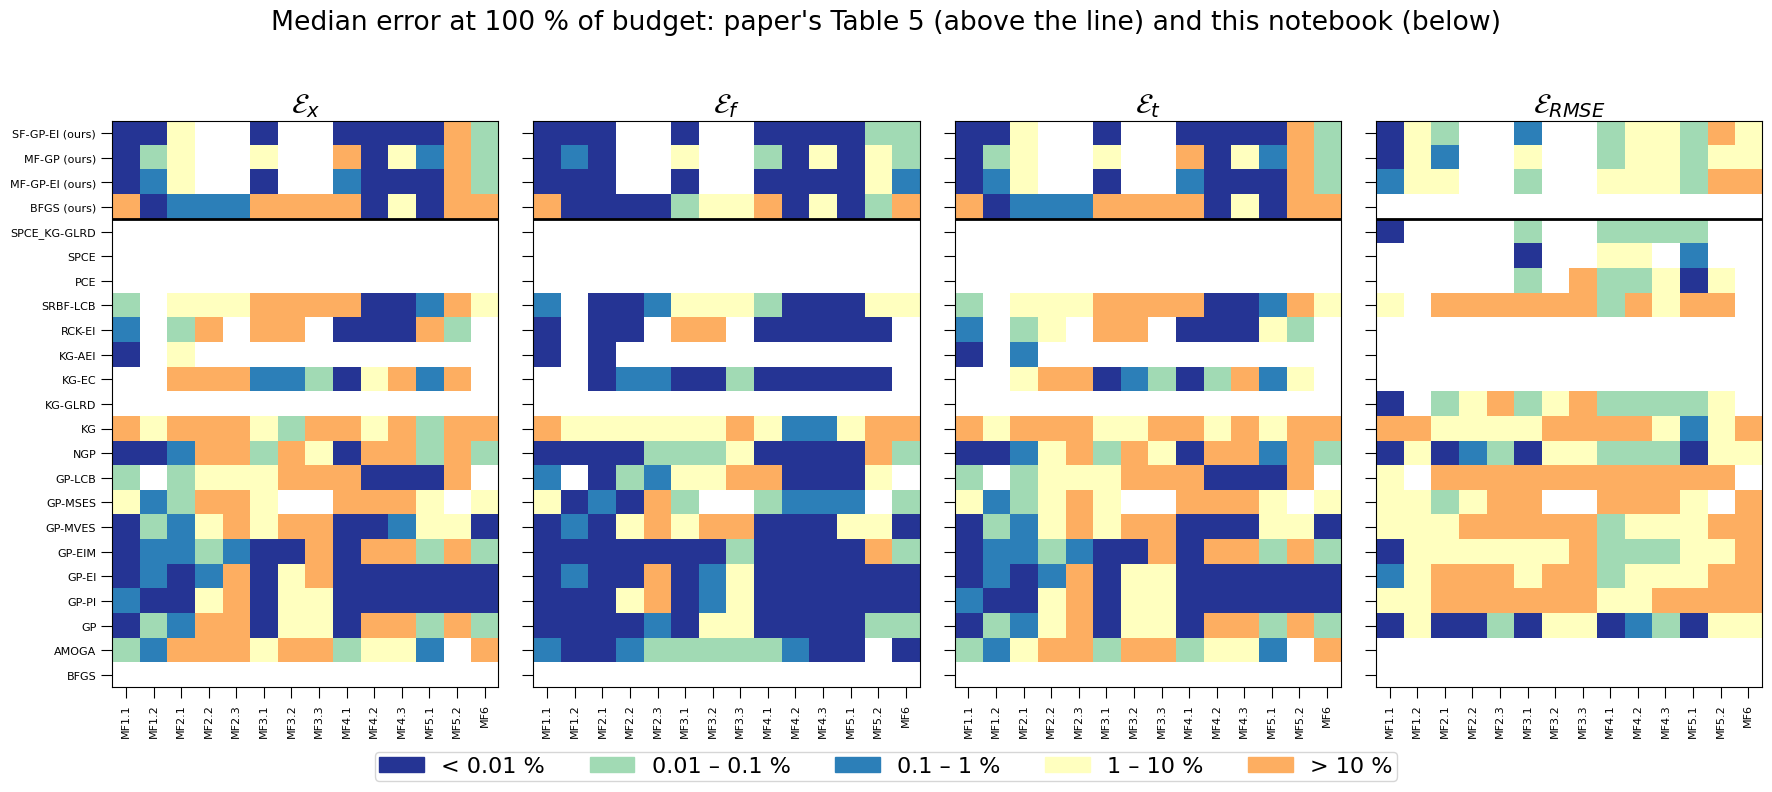

In [11]:
BANDS = "bglyo"   # <0.01 %, 0.01-0.1, 0.1-1, 1-10, >10
BAND_RGB = {"b": (37, 52, 148), "l": (44, 127, 184), "g": (161, 218, 180), "y": (255, 255, 191), "o": (253, 174, 97)}
METRICS = ["Ex", "Ef", "Et", "NRMSE"]
PCT = {0.25: "25", 0.5: "50", 0.75: "75", 1.0: "100"}


def band(err):
    if not np.isfinite(err):
        return "-"
    e = 100 * abs(err)
    return "b" if e < 0.01 else "l" if e < 0.1 else "g" if e < 1 else "y" if e < 10 else "o"


med = res.groupby(["method", "frac", "ID"])[METRICS].median()
std = res.groupby(["method", "frac", "ID"])[METRICS].std()


def our_bands(method, frac):
    s = ""
    for k, metric in enumerate(METRICS):
        for pid in PIDS:
            v = med[metric].get((method, frac, pid), np.nan)
            s += band(v)
        s += " " if k < 3 else ""
    return s


ours = {m: {PCT[f]: our_bands(m, f) for f in FRACS} for m in METHODS}


def plot_table5(budget="100"):
    rows = list(PAPER_TABLE5) + [f"{m} (ours)" for m in METHODS]
    codes = [PAPER_TABLE5[m][budget].replace(" ", "") for m in PAPER_TABLE5] + [ours[m][budget].replace(" ", "") for m in METHODS]
    idx = {c: i for i, c in enumerate(BANDS)}
    A = np.array([[idx.get(c, np.nan) for c in r] for r in codes], dtype=float)
    cmap = ListedColormap([np.array(BAND_RGB[c]) / 255 for c in BANDS])
    cmap.set_bad("white")
    fig, axes = plt.subplots(1, 4, figsize=(18, 8), sharey=True)
    for k, (ax, metric) in enumerate(zip(axes, ["$\\mathcal{E}_x$", "$\\mathcal{E}_f$", "$\\mathcal{E}_t$", "$\\mathcal{E}_{RMSE}$"])):
        ax.imshow(np.ma.masked_invalid(A[:, 14 * k:14 * (k + 1)]), cmap=cmap, vmin=-0.5, vmax=4.5, aspect="auto")
        ax.set_xticks(range(14))
        ax.set_xticklabels(PIDS, rotation=90, fontsize=8)
        ax.axhline(len(PAPER_TABLE5) - 0.5, color="k", lw=2)
        ax.set_title(metric)
    axes[0].set_yticks(range(len(rows)))
    axes[0].set_yticklabels(rows, fontsize=8)
    handles = [plt.Rectangle((0, 0), 1, 1, color=np.array(BAND_RGB[c]) / 255) for c in BANDS]
    fig.legend(handles, ["< 0.01 %", "0.01 – 0.1 %", "0.1 – 1 %", "1 – 10 %", "> 10 %"], loc="lower center", ncol=5)
    fig.suptitle(f"Median error at {budget} % of budget: paper's Table 5 (above the line) and this notebook (below)")
    plt.tight_layout(rect=(0, 0.04, 1, 0.97))


plot_table5("100")

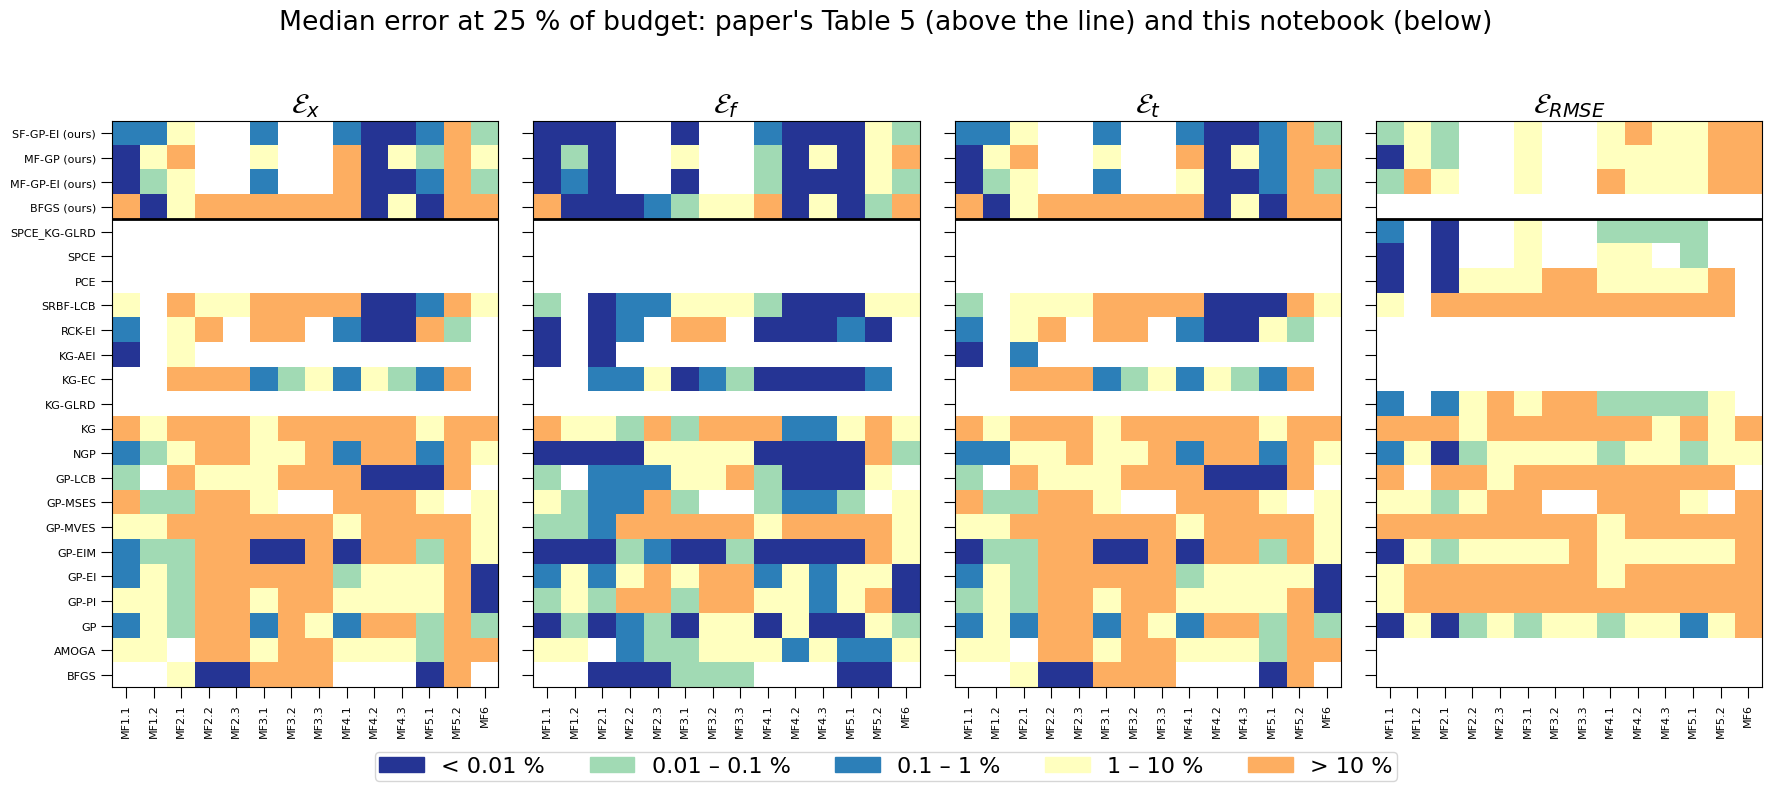

In [12]:
plot_table5("25")

### Band agreement with the matched paper methods

For each matched pair, every (budget, metric, problem) cell where both have an entry is compared. The
table gives the share of cells in the same band, the share within one band, and the mean signed
difference in bands (positive means our error is larger).

In [13]:
PAIRS = [("BFGS", "BFGS"), ("MF-GP-EI", "GP-EI"), ("MF-GP", "GP")]
rows, detail = [], []
for ours_m, paper_m in PAIRS:
    same = within1 = n = 0
    diffs = []
    for b in ["25", "50", "75", "100"]:
        a = ours[ours_m][b].replace(" ", "")
        p = PAPER_TABLE5[paper_m][b].replace(" ", "")
        for k, (ca, cp) in enumerate(zip(a, p)):
            if ca == "-" or cp == "-":
                continue
            d = BANDS.index(ca) - BANDS.index(cp)
            n += 1
            same += d == 0
            within1 += abs(d) <= 1
            diffs.append(d)
            detail.append({"pair": f"{ours_m} vs {paper_m}", "budget": b, "metric": METRICS[k // 14], "ID": PIDS[k % 14], "ours": ca, "paper": cp, "diff": d})
    rows.append({"ours": ours_m, "paper": paper_m, "cells": n, "same band": same / max(n, 1),
                 "within 1 band": within1 / max(n, 1), "mean band diff": np.mean(diffs) if diffs else np.nan})
agreement = pd.DataFrame(rows).set_index("ours")
detail = pd.DataFrame(detail)
agreement

,paper,cells,same band,within 1 band,mean band diff
ours,,,,,
BFGS,BFGS,27,0.6296,0.6667,1
MF-GP-EI,GP-EI,160,0.3937,0.625,0.0125
MF-GP,GP,160,0.425,0.6687,0.5813


In [14]:
# Where the 100 % bands differ most, by problem (mean band difference over the four metrics).
d100 = detail[detail.budget == "100"]
d100.pivot_table(index="ID", columns="pair", values="diff", aggfunc="mean").reindex(PIDS)

pair,MF-GP vs GP,MF-GP-EI vs GP-EI
ID,,
MF1.1,0,0
MF1.2,0.5,-0.5
MF2.1,1,1.25
MF2.2,NaN,NaN
MF2.3,NaN,NaN
MF3.1,3,-0.5
MF3.2,NaN,NaN
MF3.3,NaN,NaN
MF4.1,2.5,1.5


### Convergence

The paper's Figures 8–21 plot, for each problem, the median error against the percentage of budget
spent. These are the same plots for our four methods. The y-axis is log-scale, floored at $10^{-6}$ %.

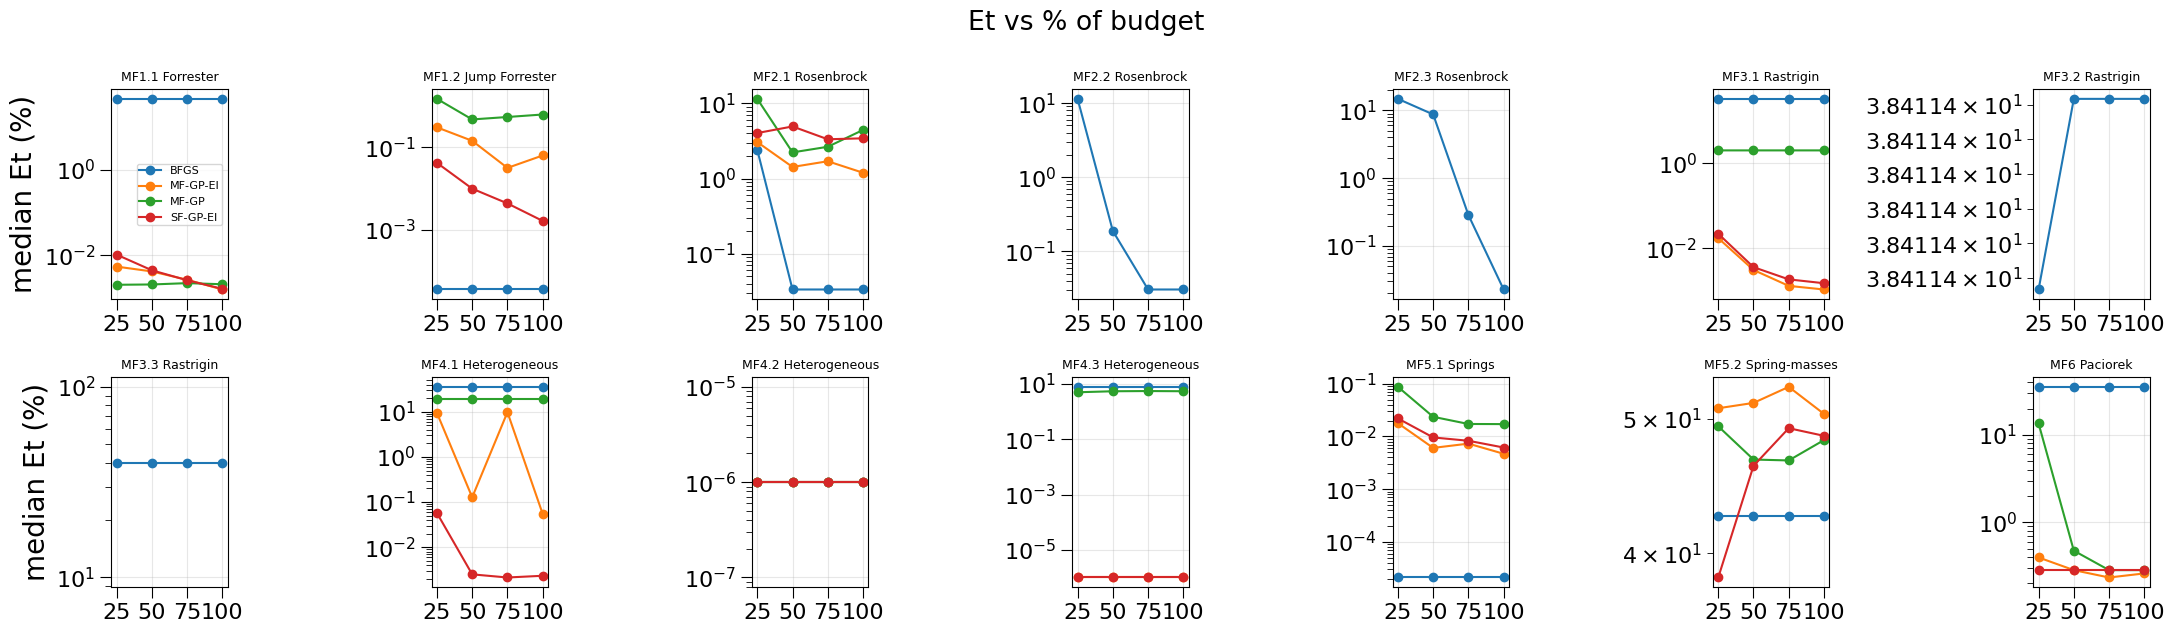

In [15]:
def plot_convergence(metric):
    fig, axes = plt.subplots(2, 7, figsize=(22, 6.5))
    for ax, pid in zip(axes.flat, PIDS):
        for m in METHODS:
            s = res[(res.ID == pid) & (res.method == m)].groupby("frac")[metric].median()
            if s.notna().any():
                ax.plot(100 * s.index, np.maximum(100 * s.abs().values, 1e-6), marker="o", label=m)
        ax.set_yscale("log")
        ax.set_title(f"{pid} {PROBLEMS[pid].name}", fontsize=9)
        ax.set_xticks([25, 50, 75, 100])
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel(f"median {metric} (%)")
    axes[1, 0].set_ylabel(f"median {metric} (%)")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{metric} vs % of budget")
    plt.tight_layout()


plot_convergence("Et")

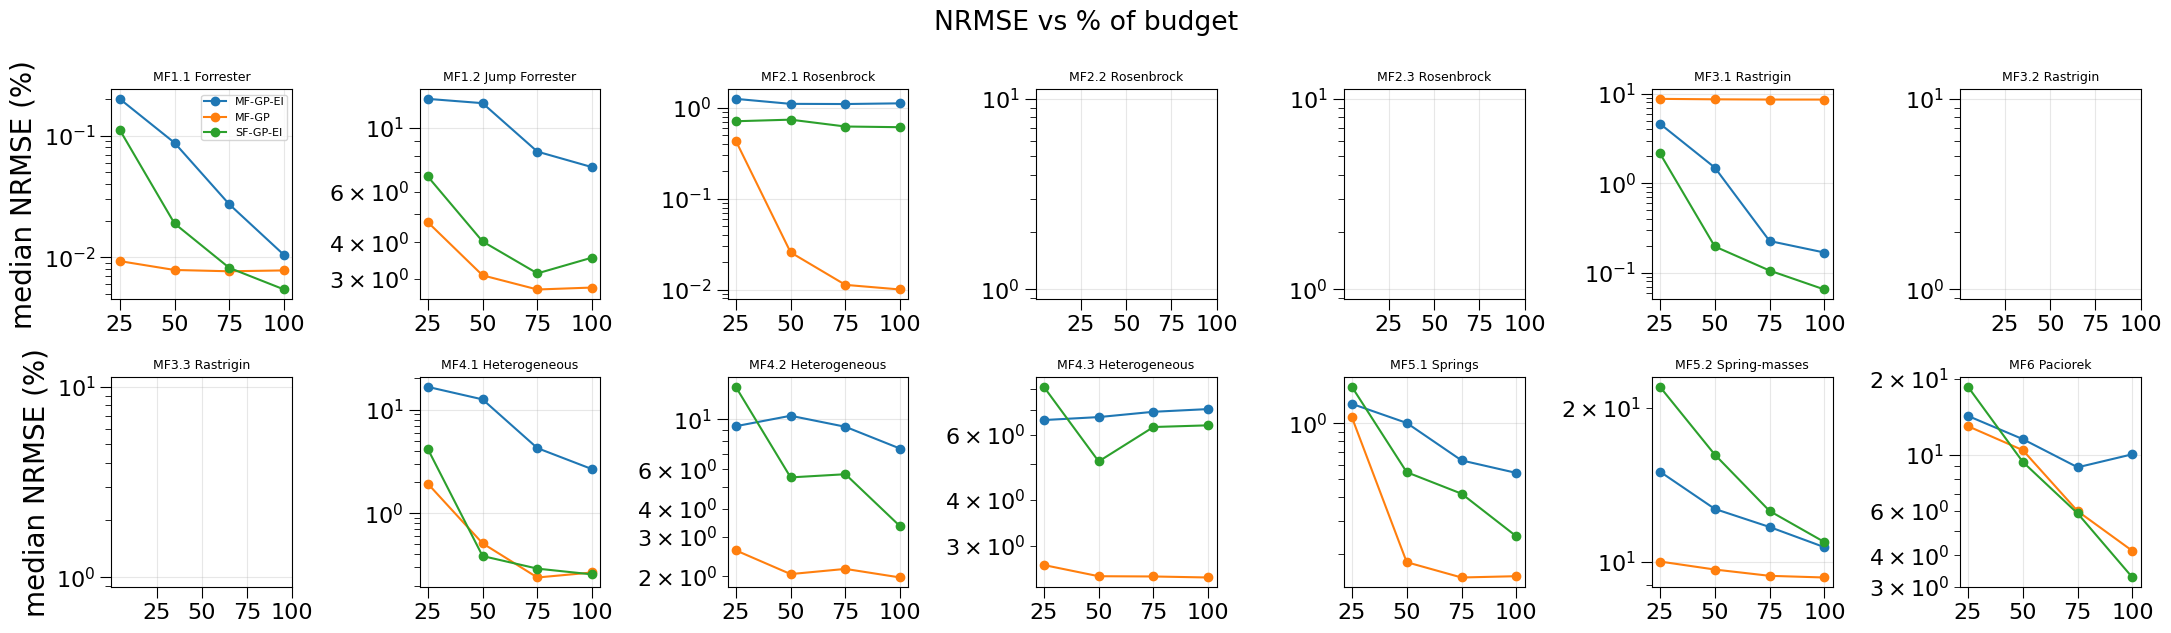

In [16]:
plot_convergence("NRMSE")

In [17]:
# Table-5-style numbers: median (std) in %, at 100 % of the budget.
tab = (100 * med.xs(1.0, level="frac")).round(4).astype(str) + " (" + (100 * std.xs(1.0, level="frac")).round(3).astype(str) + ")"
tab.unstack("method").reindex(PIDS)

Ex                                      \
method              BFGS             MF-GP          MF-GP-EI   
ID                                                             
MF1.1   61.4659 (31.741)    0.0029 (0.002)    0.0022 (0.001)   
MF1.2       0.0 (25.142)    0.8913 (0.525)     0.0897 (8.16)   
MF2.1      0.0474 (0.01)    6.2632 (7.255)    1.6908 (0.689)   
MF2.2       0.0433 (9.5)               NaN               NaN   
MF2.3     0.0323 (4.974)               NaN               NaN   
MF3.1   47.0451 (28.518)    2.5047 (0.001)    0.0015 (0.001)   
MF3.2   54.0922 (24.803)               NaN               NaN   
MF3.3   56.1671 (19.268)               NaN               NaN   
MF4.1   36.7231 (15.018)  27.5502 (14.212)    0.077 (13.274)   
MF4.2       0.0 (24.318)         0.0 (0.0)         0.0 (0.0)   
MF4.3    9.7051 (15.906)    3.1295 (1.752)         0.0 (0.0)   
MF5.1       0.0 (20.346)    0.0242 (0.022)    0.0066 (0.003)   
MF5.2   60.0549 (24.802)   67.4701 (14.22)  71.0462 (21.866)   
MF6     29.5615 (21.774)    0.2534 (0.283)    0.2246 (0.114)   

                                        Ef                                  \
method          SF-GP-EI              BFGS           MF-GP        MF-GP-EI   
ID                                                                           
MF1.1     0.0023 (0.001)  23.0403 (11.898)       0.0 (0.0)       0.0 (0.0)   
MF1.2     0.0023 (0.003)       -0.0 (7.57)   0.043 (0.047)  0.0005 (1.309)   
MF2.1     4.8503 (6.151)         0.0 (0.0)  0.0009 (0.002)    0.0001 (0.0)   
MF2.2                NaN       0.0 (0.011)             NaN             NaN   
MF2.3                NaN       0.0 (0.004)             NaN             NaN   
MF3.1     0.0021 (0.001)    0.993 (13.698)  1.3826 (0.001)       0.0 (0.0)   
MF3.2                NaN    4.1558 (5.727)             NaN             NaN   
MF3.3                NaN    2.9716 (3.542)             NaN             NaN   
MF4.1     0.0033 (0.003)  28.9071 (29.816)  0.6905 (0.356)  0.0084 (0.329)   
MF4.2          0.0 (0.0)      0.0 (11.949)       0.0 (0.0)       0.0 (0.0)   
MF4.3          0.0 (0.0)    2.4077 (4.751)  6.9526 (3.076)       0.0 (0.0)   
MF5.1     0.0087 (0.004)      0.0 (25.039)    0.0001 (0.0)       0.0 (0.0)   
MF5.2   68.7517 (35.442)    0.2354 (1.955)  8.3723 (7.254)  3.3116 (5.651)   
MF6       0.2246 (0.093)  40.4715 (26.338)  0.3333 (0.274)   0.0507 (0.16)   

                                      Et                                      \
method        SF-GP-EI              BFGS             MF-GP          MF-GP-EI   
ID                                                                             
MF1.1        0.0 (0.0)  46.4161 (23.969)    0.0021 (0.001)    0.0016 (0.001)   
MF1.2        0.0 (0.0)      0.0 (18.559)     0.631 (0.373)    0.0634 (5.844)   
MF2.1   0.0005 (0.001)    0.0335 (0.007)     4.4287 (5.13)    1.1956 (0.487)   
MF2.2              NaN    0.0306 (6.717)               NaN               NaN   
MF2.3              NaN    0.0228 (3.517)               NaN               NaN   
MF3.1        0.0 (0.0)  33.2733 (21.647)     2.023 (0.001)      0.0011 (0.0)   
MF3.2              NaN  38.4114 (17.799)               NaN               NaN   
MF3.3              NaN  40.0088 (13.705)               NaN               NaN   
MF4.1        0.0 (0.0)   35.651 (19.957)   19.487 (10.053)    0.0547 (9.389)   
MF4.2        0.0 (0.0)      0.0 (19.159)         0.0 (0.0)         0.0 (0.0)   
MF4.3        0.0 (0.0)   7.8788 (11.694)    5.4751 (2.363)         0.0 (0.0)   
MF5.1        0.0 (0.0)      0.0 (22.801)    0.0171 (0.016)    0.0047 (0.002)   
MF5.2   0.2082 (0.546)  42.5689 (17.548)  48.2753 (10.562)  50.4186 (15.378)   
MF6     0.3333 (0.154)  35.4389 (23.533)    0.2842 (0.251)    0.2606 (0.102)   

                             NRMSE                                   \
method         SF-GP-EI       BFGS           MF-GP         MF-GP-EI   
ID                                                                    
MF1.1      0.0016 (0.0)  nan (na

## 8. The paper's findings, checked

Each claim in the paper's Section 6 that the four methods here can test is turned into a quantitative
check on the results above. Claims about methods that cannot be reproduced (PCE, KG-GLRD, NGP, ...) are
left out.

In [18]:
def m(method, pid, metric, frac=1.0):
    return float(med[metric].get((method, frac, pid), np.nan))


def s(method, pid, metric, frac=1.0):
    return float(std[metric].get((method, frac, pid), np.nan))


bfgs_spread = {pid: s("BFGS", pid, "Et") for pid in PIDS}
checks = [
    ("Rosenbrock 2-D is unimodal, so BFGS converges well (median Et < 1 % at 100 %).",
     m("BFGS", "MF2.1", "Et") < 0.01, f"Et = {100 * m('BFGS', 'MF2.1', 'Et'):.3g} %"),
    ("For multimodal cases (Rastrigin, springs, Rosenbrock 5-D) the BFGS result depends on the start: "
     "spread over starts is larger than on Rosenbrock 2-D.",
     min(bfgs_spread[p] for p in ["MF3.1", "MF3.2", "MF5.1", "MF5.2", "MF2.2"]) > bfgs_spread["MF2.1"],
     ", ".join(f"{p}: {100 * bfgs_spread[p]:.2g} %" for p in ["MF2.1", "MF2.2", "MF3.1", "MF3.2", "MF5.1", "MF5.2"])),
    ("Forrester: GP-type methods give a globally accurate surrogate (NRMSE in the dark-blue band, < 0.01 %).",
     min(m("MF-GP", "MF1.1", "NRMSE"), m("MF-GP-EI", "MF1.1", "NRMSE")) < 1e-4,
     f"MF-GP {100 * m('MF-GP', 'MF1.1', 'NRMSE'):.2g} %, MF-GP-EI {100 * m('MF-GP-EI', 'MF1.1', 'NRMSE'):.2g} %"),
    ("Jump Forrester: no method gives a particularly good global model (every NRMSE > 1 %).",
     all(m(x, "MF1.2", "NRMSE") > 0.01 for x in METHODS[1:]),
     ", ".join(f"{x} {100 * m(x, 'MF1.2', 'NRMSE'):.2g} %" for x in METHODS[1:])),
    ("Heterogeneous 2-D/3-D: the optimum is the boundary face x1 = 0, which some methods find at once "
     "(median Et < 0.01 % already at 25 %).",
     any(m(x, "MF4.2", "Et", 0.25) < 1e-4 for x in METHODS[1:]),
     ", ".join(f"{x} {100 * m(x, 'MF4.2', 'Et', 0.25):.2g} %" for x in METHODS[1:])),
    ("Heterogeneous: NRMSE convergence is fairly flat in 3-D (MF-GP-EI improves by less than 10x from 25 % to 100 %).",
     m("MF-GP-EI", "MF4.3", "NRMSE", 0.25) / m("MF-GP-EI", "MF4.3", "NRMSE") < 10,
     f"{100 * m('MF-GP-EI', 'MF4.3', 'NRMSE', 0.25):.3g} % -> {100 * m('MF-GP-EI', 'MF4.3', 'NRMSE'):.3g} %"),
    ("Springs: GP-EI does well for optimization in 2-D (median Et < 1 %).",
     m("MF-GP-EI", "MF5.1", "Et") < 0.01, f"Et = {100 * m('MF-GP-EI', 'MF5.1', 'Et'):.3g} %"),
    ("Springs: global-accuracy convergence is sluggish (best NRMSE in 4-D stays above 1 %).",
     min(m(x, "MF5.2", "NRMSE") for x in METHODS[1:]) > 0.01,
     ", ".join(f"{x} {100 * m(x, 'MF5.2', 'NRMSE'):.2g} %" for x in METHODS[1:])),
    ("Paciorek (noisy): GP-EI does well for optimization (median Et < 1 %).",
     m("MF-GP-EI", "MF6", "Et") < 0.01, f"Et = {100 * m('MF-GP-EI', 'MF6', 'Et'):.3g} %"),
]
pd.DataFrame(checks, columns=["Paper's claim (as a test)", "Reproduced", "Evidence"])

,Paper's claim (as a test),Reproduced,Evidence
0,"Rosenbrock 2-D is unimodal, so BFGS converges ...",True,Et = 0.0335 %
1,"For multimodal cases (Rastrigin, springs, Rose...",True,"MF2.1: 0.007 %, MF2.2: 6.7 %, MF3.1: 22 %, MF3..."
2,Forrester: GP-type methods give a globally acc...,True,"MF-GP 0.0078 %, MF-GP-EI 0.01 %"
3,Jump Forrester: no method gives a particularly...,True,"MF-GP-EI 7.3 %, MF-GP 2.8 %, SF-GP-EI 3.5 %"
4,Heterogeneous 2-D/3-D: the optimum is the boun...,True,"MF-GP-EI 5e-09 %, MF-GP 5e-09 %, SF-GP-EI 5e-09 %"
5,Heterogeneous: NRMSE convergence is fairly fla...,True,6.59 % -> 7.06 %
6,Springs: GP-EI does well for optimization in 2...,True,Et = 0.00469 %
7,Springs: global-accuracy convergence is sluggi...,True,"MF-GP-EI 11 %, MF-GP 9.3 %, SF-GP-EI 11 %"
8,Paciorek (noisy): GP-EI does well for optimiza...,True,Et = 0.261 %


### Beyond the paper: does multi-fidelity beat high-fidelity only?

The paper deliberately leaves out single-fidelity counterparts. Here the multi-fidelity EI run is set
against single-fidelity EI at the same cost. A ratio below 1 means the multi-fidelity run did better. Errors are floored at $10^{-4}$ %, so two runs that both found the optimum show a ratio of 1. The level correlations from Section 3c are shown alongside.

In [19]:
FLOOR = 1e-6  # 1e-4 %: below this both methods have effectively found the optimum
rows = []
for pid in SURROGATE_PIDS:
    r = {"ID": pid}
    for metric in ["Et", "NRMSE"]:
        a, b = (max(abs(m(x, pid, metric)), FLOOR) for x in ("MF-GP-EI", "SF-GP-EI"))
        r[f"{metric} MF (%)"], r[f"{metric} SF (%)"], r[f"{metric} MF/SF"] = 100 * a, 100 * b, a / b
    rows.append(r)
pd.DataFrame(rows).set_index("ID").join(corr)

,Et MF (%),Et SF (%),Et MF/SF,NRMSE MF (%),NRMSE SF (%),NRMSE MF/SF,f2,f3,f4
ID,,,,,,,,,
MF1.1,0.001561,0.001619,0.9641,0.01043,0.00543,1.92,0.9455,0.9374,0.7357
MF1.2,0.06343,0.001619,39.17,7.292,3.546,2.057,0.962,NaN,NaN
MF2.1,1.196,3.43,0.3486,1.125,0.6147,1.831,0.9999,0.9982,NaN
MF3.1,0.001054,0.001483,0.7111,0.1682,0.06499,2.587,0.9722,0.9377,NaN
MF4.1,0.05474,0.002332,23.47,2.661,0.2569,10.36,0.8643,NaN,NaN
MF4.2,0.0001,0.0001,1,7.411,3.336,2.222,0.9465,NaN,NaN
MF4.3,0.0001,0.0001,1,7.058,6.374,1.107,0.9569,NaN,NaN
MF5.1,0.004688,0.006161,0.7609,0.5416,0.2475,2.189,0.8769,NaN,NaN
MF5.2,50.42,48.62,1.037,10.67,10.92,0.9772,0.9878,NaN,NaN


## 9. Summary and limitations

**Reproduced exactly:** all 14 benchmark definitions. At the authors' published minimizers our functions
match their reference $f_{\min}$ to about $10^{-9}$ (Section 3a). The global search in Section 3b
recovers every Table 4 optimum, including the two cases (MF1.2, MF6) that the authors' CSV does not
cover. The text-vs-code differences in Section 2 are the things to watch when porting these problems
from the paper alone.

**Reproduced in kind:** the protocol (budgets, cost ratios, metrics, checkpoints, 10 runs) and the
qualitative findings checked in Section 8. Band-level agreement with Table 5 is approximate by
construction, for these reasons:

* The paper's methods differ in DoE, hyperparameter fitting, inner optimizer and acquisition details
  (Table 3), and their code is not public. MF-GP-EI is a stand-in for GP-EI, not a re-implementation.
* This notebook's BFGS uses $f_1$ only. The paper's is multi-fidelity. The paper also drops converged
  BFGS runs from its averages, which is why most of its BFGS cells after 25 % are empty.
* Adaptive methods refit in 20 rounds rather than after every point. The lowest level is capped at 200
  points.
* $\mathcal{E}_x$ is measured to the single optimum Table 4 gives. **MF5.2 has more than one global
  minimizer.** The search in Section 3b reaches $f_1 = -1$ at a design about 1.4 (unit-cube distance)
  from the Table 4 point, so $\mathcal{E}_x$ near 50 % there, alongside a small $\mathcal{E}_f$, is an
  artefact of the metric and not a failure of the methods.
* Multi-fidelity EI did not reliably beat single-fidelity EI at equal cost (Section 8, last table). The
  run-to-run spread of the cheap levels and the 25 % floor on $f_1$ spending both matter. The paper never
  ran this comparison.
* The 5-D and 10-D cases run for BFGS only unless `RUN_HIGH_D = True`.